In [13]:
import sys

sys.path.append("..")
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime
import os
import json
from typing import List, Optional
from tqdm import tqdm
# from classes.peak.peak_classes import PeakRecord
import matplotlib.pyplot as plt
from dataclasses import asdict


In [ ]:
# import scienceplots
# plt.style.use(["science", "ieee", "grid"])

In [20]:
# AXES = ["x", "y", "z"]
AXES = ["r", "x"]
RADIALS = ["y", "z"]
CABLES = [1, 2, 3, 4]

In [ ]:
SEQ_1_PATH = Path("../data/frf_peaks/sequence_1/")
SEQ_2_PATH = Path("../data/frf_peaks/sequence_2/")
SEQ_3_PATH = Path("../data/frf_peaks/sequence_3/")


In [ ]:
SAMPLES_TO_AVOID = [
    datetime(2023, 2, 20, 7, 59, 0),
    datetime(2023, 3, 3, 23, 20, 0),
    datetime(2023, 3, 5, 15, 21, 0),
    datetime(2023, 3, 7, 5, 21, 0),
    datetime(2023, 5, 19, 19, 16),
    datetime(2023, 5, 29, 19, 16),
    datetime(2023, 6, 1, 11, 39),
]

In [ ]:
VALID_START_DATE_S1 = datetime(2023, 1, 15)

VALID_START_DATE_S2 = datetime(2023, 4, 27, 11)
VALID_END_DATE_S2 = datetime(2023, 7, 5, 11)

VALID_START_DATE_S3 = datetime(2023, 8, 15, 15)

SEQ_1_HEALTH_END = datetime(2023, 1, 25, 10, 0, 0)
SEQ_2_HEALTH_END = datetime(2023, 5, 9, 11, 0, 0)
SEQ_3_HEALTH_END = datetime(2023, 8, 30, 11, 0, 0)

# Helper functions

In [ ]:
from dataclasses import dataclass

In [ ]:
@dataclass
class PeakRecord:
    sample_id: str
    tension: float
    axis: str
    cable: int
    frequency: list[float]
    magnitude: list[float]


In [ ]:
def load_and_transform_features(
    path: Path,
    valid_start: Optional[datetime] = None,
    valid_end: Optional[datetime] = None,
    samples_to_avoid: Optional[List[datetime]] = None,
    max_samples: Optional[int] = None,
) -> tuple[List[PeakRecord], List[PeakRecord]]:
    files = os.listdir(path / "radial") # should be the same for axial
    peaks_r: List[PeakRecord] = []
    peaks_x: List[PeakRecord] = []
    counter = 0
    for file in tqdm(files):
        with open(path / "radial" / file, "r") as f:
            data_r = json.load(f)
        with open(path / "axial" / file, "r") as f:
            data_x = json.load(f)
        pr = PeakRecord(**data_r)
        date = datetime.fromisoformat(pr.sample_id)
        if samples_to_avoid and date in samples_to_avoid:
            continue
        if valid_start and date < valid_start:
            continue
        if valid_end and date > valid_end:
            continue
        px = PeakRecord(**data_x)
        peaks_r.append(pr)
        peaks_x.append(px)
        counter += 1
        if max_samples and counter >= max_samples:
            break
    return peaks_r, peaks_x

In [ ]:
peaks_r_s1, peaks_x_s1 = load_and_transform_features(SEQ_1_PATH)
peaks_r_s2, peaks_x_s2 = load_and_transform_features(SEQ_2_PATH)
peaks_r_s3, peaks_x_s3 = load_and_transform_features(SEQ_3_PATH)

In [29]:
def get_indexes(k: int, data: List[float]) -> List[int]:
    data_arr = np.array(data)
    data_max = np.max(data_arr)
    data_min = np.min(data_arr)
    delta = (data_max - data_min) / k
    values = np.arange(data_min, data_max, delta)
    diffs = np.abs(np.subtract.outer(data_arr, values))
    return np.argmin(diffs, axis=0)

In [16]:
peaks_df = pd.DataFrame([asdict(d) for d in peaks_r_s1])
peaks_df = pd.concat([peaks_df, pd.json_normalize(peaks_df["frequency"])], axis=1)

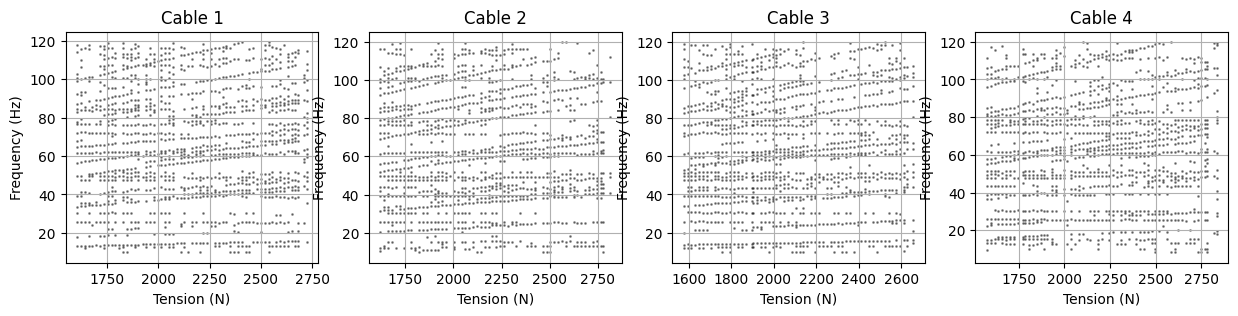

In [52]:
k = 60

plt.figure(figsize=(15, 3))
for i, cable in enumerate(CABLES):
    plt.subplot(1, len(CABLES), i + 1)
    plt.title(f"Cable {cable}")
    cable_df = peaks_df.loc[peaks_df.cable == cable]
    cable_df = cable_df.sort_values(by="tension")
    ind = get_indexes(k=k, data=cable_df.tension)
    selected_df = cable_df.iloc[ind]
    for _, row in selected_df.iterrows():
        plt.scatter(
            [row["tension"]] * len(row["frequency"]), row["frequency"], alpha=0.4, s=1, color="k"
            # [row["tension"]] * len(row["frequency"]), row["frequency"], alpha=0.5, s=row["magnitude"], color="k"
        )
        # plt.ylim(8, 56)
        # plt.title(f"Axis {axis}, Cable {cable}")
        # plt.yticks(np.arange(8, 56 + 1, 8))
        plt.xlabel("Tension (N)")
        plt.ylabel("Frequency (Hz)")
        plt.grid(True)

In [ ]:
for cable in CABLES:
    plt.figure(figsize=(10, 3))
    for i, axis in enumerate(AXES):
        temp = peaks_df.loc[(peaks_df.axis == axis) & (peaks_df.cable == cable)].copy()
        temp["sample_id"] = pd.to_datetime(temp["sample_id"])
        temp = temp.sort_values(by="tension")
        plt.subplot(1, 3, i + 1)
        plt.scatter(temp["tension"], temp["frequency"], alpha=0.1, s=0.5)
        plt.ylim(56, 120)
        plt.yticks(np.arange(56, 120 + 1, 8))
        plt.title(f"Axis {axis}, Cable {cable}")
        plt.xlabel("Tension (N)")
        plt.ylabel("Frequency (Hz)")
        plt.grid(True)


In [ ]:
frfs_coh = load_and_transform_features(SEQ_1_COH_PATH, valid_start=VALID_START_DATE_S1)

In [ ]:
metadata = [
    {
        "i": i,
        "sample_id": frf.sample_id,
        "tension_c1": frf.sample_c1.tension,
        "tension_c2": frf.sample_c2.tension,
        "tension_c3": frf.sample_c3.tension,
        "tension_c4": frf.sample_c4.tension,
    }
    for i, frf in enumerate(frfs_h2)
]
metadata = pd.DataFrame(metadata)

## Selecting K samples equality spaced (approx)

In [ ]:
metadata["avg_tension"] = metadata[
    ["tension_c1", "tension_c2", "tension_c3", "tension_c4"]
].mean(axis=1)

In [ ]:
k = 20
idx = get_indexes(k, metadata["avg_tension"])

selected_frfs = [frfs_h2[i] for i in idx]
selected_cohs = [frfs_coh[i] for i in idx]

In [ ]:
# plot_2d_pcolormesh_cables_axes(
#     frf_list=frfs_h2, db=True, combine_axes=True, f_min=8.0, f_max=128.0, log_x=False
# )

In [ ]:
# plot_2d_pcolormesh_cables_axes(
#     frf_list=frfs_h2, db=True, combine_axes=True, f_min=8.0, f_max=32.0, log_x=True
# )

# COH

In [ ]:
def get_matrices(frfs_coh, cable, axis):
    c = []
    t = []
    f = None
    for frf in frfs_coh:
        single_frf = getattr(frf, f"sample_c{cable}")
        t.append(single_frf.tension)
        axis_frf = getattr(single_frf, f"{axis}")
        if f is None:
            f = axis_frf.frequencies
        c.append(axis_frf.abs)
    c = np.array(c)
    return t, f, c

In [ ]:
t1, f1, cx1 = get_matrices(frfs_coh, "1", "x")
_, _, cy1 = get_matrices(frfs_coh, "1", "y")
_, _, cz1 = get_matrices(frfs_coh, "1", "z")

t2, f2, cx2 = get_matrices(frfs_coh, "2", "x")
_, _, cy2 = get_matrices(frfs_coh, "2", "y")
_, _, cz2 = get_matrices(frfs_coh, "2", "z")

t3, f3, cx3 = get_matrices(frfs_coh, "3", "x")
_, _, cy3 = get_matrices(frfs_coh, "3", "y")
_, _, cz3 = get_matrices(frfs_coh, "3", "z")

t4, f4, cx4 = get_matrices(frfs_coh, "4", "x")
_, _, cy4 = get_matrices(frfs_coh, "4", "y")
_, _, cz4 = get_matrices(frfs_coh, "4", "z")

cr1 = np.max(np.stack([cy1, cz1]), axis=0)
cr2 = np.max(np.stack([cy2, cz2]), axis=0)
cr3 = np.max(np.stack([cy3, cz3]), axis=0)
cr4 = np.max(np.stack([cy4, cz4]), axis=0)

In [ ]:
plot_3d_waterfall_one_plot_per_cable(
    selected_cohs,
    cables=["1", "2", "3", "4"],
    axes_list=["x", "y", "z"],
    f_min=0.0,
    f_max=64.0,
    combine_axes=True,
    db=False,
    seq=0,
)

In [ ]:
plot_3d_waterfall_one_plot_per_cable(
    selected_frfs,
    cables=["1", "2", "3", "4"],
    axes_list=["x", "y", "z"],
    f_min=8.0,
    f_max=120.0,
    combine_axes=True,
    db=False,
    seq=0,
)

In [ ]:
def plot_frf_and_coh(
    frf: SampleFRF,
    coh: SampleFRF,
    index: int,
    f_min: Optional[float] = None,
    f_max: Optional[float] = None,
    db_scale: bool = False,
):
    for cable in CABLES:
        # Two rows, one column.
        # The top row is 2x taller than the bottom row.
        fig, (ax_mag, ax_coh) = plt.subplots(
            2, 1, gridspec_kw={"height_ratios": [2, 1]}, figsize=(6, 2)
        )

        # We will store labels for the legend only once
        labels = []

        for axis in AXES:
            single_frf: SignalFRF = getattr(frf, f"sample_c{cable}").__getattribute__(
                axis
            )
            single_coh: SignalFRF = getattr(coh, f"sample_c{cable}").__getattribute__(
                axis
            )

            freq = np.array(single_frf.frequencies)
            mag = np.array(single_frf.abs)
            coh_mag = np.array(single_coh.abs)

            # Apply frequency mask if f_min/f_max are provided
            if isinstance(f_min, float) and isinstance(f_max, float):
                mask = (freq >= f_min) & (freq <= f_max)
                freq = freq[mask]
                mag = mag[mask]
                coh_mag = coh_mag[mask]

            # Convert to dB if requested
            if db_scale:
                mag = 20 * np.log10(mag)

            # Plot FRF magnitude on the first (taller) subplot
            ax_mag.plot(freq, mag)
            # Plot coherence on the second (shorter) subplot
            ax_coh.plot(freq, coh_mag)
            labels.append(f"Axis {axis}")

        # Set labels, limits, legends for the top subplot
        ax_mag.set_xlim([freq.min(), freq.max()])
        # ax_mag.set_xlabel("Frequency (Hz)")
        ax_mag.set_ylabel("Magnitude (dB)" if db_scale else "Magnitude (g/N)")
        ax_mag.legend(labels, ncols=3, loc="lower right")

        # Set labels, limits for the bottom subplot
        ax_coh.set_xlim([freq.min(), freq.max()])
        ax_coh.set_xlabel("Frequency (Hz)")
        ax_coh.set_ylabel("Coherence")
        ax_coh.set_ylim([0, 1])  # Optional, if you want it fixed between 0..1

        # Adjust layout
        plt.tight_layout()
        plt.savefig(f"figures_frf_eda/frf_index{index}_cable{cable}.png", dpi=300)
        plt.show()

In [ ]:
# plot_frf_and_coh(
#     selected_frfs[0],
#     selected_cohs[0],
#     index=0,
#     f_min=0.0,
#     f_max=128.0,
#     db_scale=True,
# )

# PSD

In [ ]:
from classes.signal.signal_classes import SignalSpectrum
from classes.sample.sample_classes import SinglePSDSample, SamplePSD

In [ ]:
def load_and_transform_psds(
    path: Path,
    valid_start: Optional[datetime] = None,
    valid_end: Optional[datetime] = None,
    max_samples: Optional[int] = None,
    samples_to_avoid: Optional[List[datetime]] = None,
) -> List[SampleFRF]:
    files = os.listdir(path)
    frfs: List[SampleFRF] = []
    counter = 0
    for file in tqdm(files):
        with open(path / file, "r") as f:
            data = json.load(f)
        sample_frf = SamplePSD(**data)
        date = datetime.fromisoformat(sample_frf.sample_id)
        if samples_to_avoid and date in samples_to_avoid:
            continue
        if valid_start and date < valid_start:
            continue
        if valid_end and date > valid_end:
            continue
        frfs.append(sample_frf)
        counter += 1
        if max_samples and counter >= max_samples:
            break
    return frfs

In [ ]:
def convert_psd_obj(psd: SamplePSD) -> SampleFRF:
    sample_frf_data = {"sample_id": psd.sample_id}
    for cable in CABLES:
        data = {
            "x": None,
            "y": None,
            "z": None,
            "tension": getattr(psd, f"sample_c{cable}").tension,
        }
        for axis in AXES:
            single_psd: SignalSpectrum = getattr(
                psd, f"sample_c{cable}"
            ).__getattribute__(axis)
            data[axis] = SignalFRF(
                frequencies=single_psd.frequencies,
                abs=single_psd.magnitudes,
                angle=[0] * len(single_psd.frequencies),
            )
        sample_frf_data[f"sample_c{cable}"] = SingleFRFSample(**data)
    return SampleFRF(**sample_frf_data)

In [ ]:
SEQ_1_PSD_PATH = Path("../data/psds/sequence_1")

In [ ]:
psds = load_and_transform_psds(
    SEQ_1_PSD_PATH, valid_start=VALID_START_DATE_S1, samples_to_avoid=SAMPLES_TO_AVOID
)

In [ ]:
psds = [convert_psd_obj(psd) for psd in psds]

# PSD Peaks

In [ ]:
psd_peaks = []

for cable in CABLES:
    for axis in AXES:
        for psd in psds:
            peaks = get_peaks(
                psd.__getattribute__(f"sample_c{cable}").__getattribute__(axis),
            )
            records = [
                Record(
                    sample_id=psd.sample_id,
                    tension=psd.__getattribute__(f"sample_c{cable}").tension,
                    axis=axis,
                    cable=cable,
                    peak=peak,
                )
                for peak in peaks
            ]
            psd_peaks += records

In [ ]:
peaks_df = pd.DataFrame([d.model_dump() for d in psd_peaks])
peaks_df = pd.concat([peaks_df, pd.json_normalize(peaks_df["peak"])], axis=1)

In [ ]:
for cable in CABLES:
    plt.figure(figsize=(10, 3))
    for i, axis in enumerate(AXES):
        temp = peaks_df.loc[(peaks_df.axis == axis) & (peaks_df.cable == cable)].copy()
        temp["sample_id"] = pd.to_datetime(temp["sample_id"])
        temp = temp.sort_values(by="tension")
        plt.subplot(1, 3, i + 1)
        plt.scatter(temp["tension"], temp["frequency"], alpha=0.1, s=0.5)
        plt.ylim(8, 56)
        plt.title(f"Axis {axis}, Cable {cable}")
        plt.ylabel("Frequency (Hz)")
        plt.xlabel("Tension (N)")
        plt.yticks(np.arange(8, 56 + 1, 8))
        plt.grid(True)

In [ ]:
for cable in CABLES:
    plt.figure(figsize=(10, 3))
    for i, axis in enumerate(AXES):
        temp = peaks_df.loc[(peaks_df.axis == axis) & (peaks_df.cable == cable)].copy()
        temp["sample_id"] = pd.to_datetime(temp["sample_id"])
        temp = temp.sort_values(by="tension")
        plt.subplot(1, 3, i + 1)
        plt.scatter(temp["tension"], temp["frequency"], alpha=0.1, s=0.5)
        plt.ylim(56, 120)
        plt.title(f"Axis {axis}, Cable {cable}")
        plt.yticks(np.arange(56, 120 + 1, 8))
        plt.grid(True)

In [ ]:
metadata = [
    {
        "i": i,
        "sample_id": psd.sample_id,
        "tension_c1": psd.sample_c1.tension,
        "tension_c2": psd.sample_c2.tension,
        "tension_c3": psd.sample_c3.tension,
        "tension_c4": psd.sample_c4.tension,
    }
    for i, psd in enumerate(psds)
]
metadata = pd.DataFrame(metadata)

metadata["avg_tension"] = metadata[
    ["tension_c1", "tension_c2", "tension_c3", "tension_c4"]
].mean(axis=1)

In [ ]:
k = 20
idx = get_indexes(k, metadata["avg_tension"])

selected_psds = [psds[i] for i in idx]

In [ ]:
plot_3d_waterfall_one_plot_per_cable(
    selected_psds,
    cables=["1", "2", "3", "4"],
    axes_list=["x", "y", "z"],
    f_min=8.0,
    f_max=120.0,
    combine_axes=False,
    db=False,
    seq=0,
    mode="psd",
)

In [ ]:
plot_2d_pcolormesh_cables_axes(
    frf_list=psds,
    db=True,
    combine_axes=True,
    f_min=8.0,
    f_max=120.0,
    log_x=False,
    mode="psd",
)

In [ ]:
plot_2d_pcolormesh_cables_axes(
    frf_list=psds,
    db=True,
    combine_axes=True,
    f_min=8.0,
    f_max=32.0,
    log_x=True,
    mode="psd",
)